### 🧠 Lab23: MLPClassifier

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from sklearn.datasets import load_digits
from sklearn.model_selection import train_test_split
from sklearn.neural_network import MLPClassifier
from sklearn.metrics import classification_report, confusion_matrix, accuracy_score
import seaborn as sns

print("¡Librerías cargadas correctamente!")

¡Librerías cargadas correctamente!


In [2]:
# Cargar el dataset
digits = load_digits()

# Inspeccionar las dimensiones de los datos
print(f"Número total de imágenes: {digits.images.shape[0]}")
print(f"Tamaño de cada imagen: {digits.images.shape[1]}x{digits.images.shape[2]} píxeles")
print(f"Dimensiones de la matriz de características (X): {digits.data.shape}")
print(f"Dimensiones del vector de etiquetas (y): {digits.target.shape}")

Número total de imágenes: 1797
Tamaño de cada imagen: 8x8 píxeles
Dimensiones de la matriz de características (X): (1797, 64)
Dimensiones del vector de etiquetas (y): (1797,)


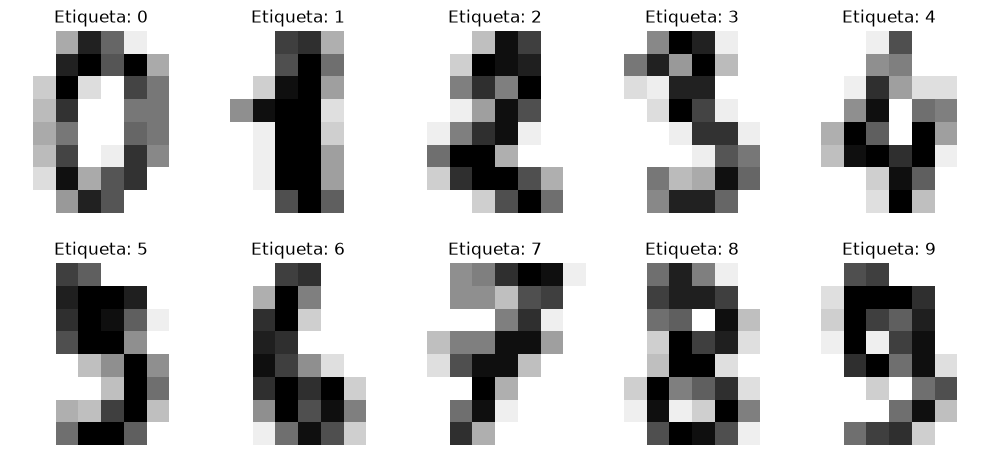

In [3]:
# Visualizar algunos ejemplos
# Veamos cómo lucen las imágenes en el dataset y sus respectivas etiquetas.
fig, axes = plt.subplots(2, 5, figsize=(10, 5))
for i, ax in enumerate(axes.flat):
    ax.imshow(digits.images[i], cmap='gray_r')
    ax.set_title(f"Etiqueta: {digits.target[i]}")
    ax.axis('off')
plt.tight_layout()
plt.show()

In [4]:
# Paso 3: Preparación de los Datos (División Train / Test)
X = digits.data
y = digits.target

# Dividir 80% entrenamiento y 20% prueba
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

print(f"Muestras para entrenamiento: {X_train.shape[0]}")
print(f"Muestras para prueba: {X_test.shape[0]}")

Muestras para entrenamiento: 1437
Muestras para prueba: 360


In [5]:
# Paso 4: Creación y Entrenamiento del Modelo MLP
# Usaremos `MLPClassifier` de `scikit-learn`, que representa un **Perceptrón Multicapa** (Multilayer Perceptron).
# Instanciar el modelo de Red Neuronal
mlp = MLPClassifier(
    hidden_layer_sizes=(64, 32),
    activation='relu',
    max_iter=300,
    random_state=42
)

# Entrenar la red neuronal
print("Entrenando la red neuronal...")
mlp.fit(X_train, y_train)
print("¡Entrenamiento completado!")

Entrenando la red neuronal...
¡Entrenamiento completado!


In [6]:
# Paso 5: Evaluación del Modelo
# Realizar predicciones
y_pred = mlp.predict(X_test)

# Calcular precisión general
precisión = accuracy_score(y_test, y_pred)
print(f"🎯 Precisión global del modelo (Accuracy): {precisión * 100:.2f}%")

# Reporte detallado de clasificación
print("\n📋 Reporte de Clasificación:")
print(classification_report(y_test, y_pred))

🎯 Precisión global del modelo (Accuracy): 96.67%

📋 Reporte de Clasificación:
              precision    recall  f1-score   support

           0       1.00      1.00      1.00        33
           1       0.93      1.00      0.97        28
           2       0.97      0.97      0.97        33
           3       0.97      0.97      0.97        34
           4       1.00      1.00      1.00        46
           5       0.96      0.96      0.96        47
           6       0.97      0.97      0.97        35
           7       1.00      0.97      0.99        34
           8       0.93      0.87      0.90        30
           9       0.93      0.95      0.94        40

    accuracy                           0.97       360
   macro avg       0.97      0.97      0.97       360
weighted avg       0.97      0.97      0.97       360



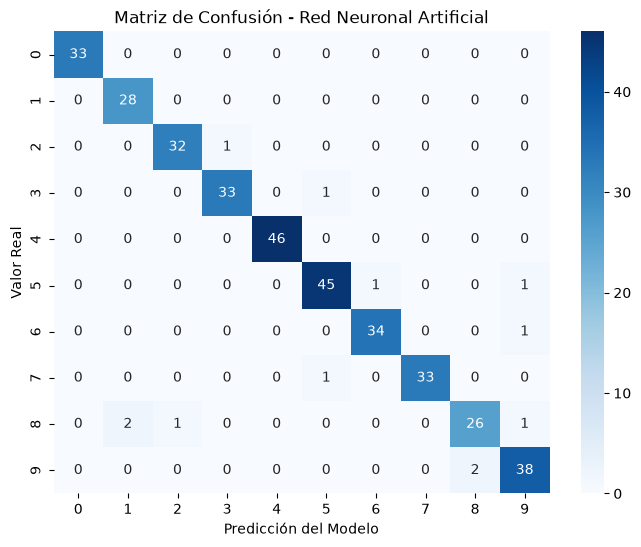

In [7]:
# La matriz de confusión nos ayuda a ver dónde se confundió la red al clasificar los dígitos.
# Matriz de Confusión
cm = confusion_matrix(y_test, y_pred)

plt.figure(figsize=(8, 6))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', xticklabels=digits.target_names, yticklabels=digits.target_names)
plt.xlabel('Predicción del Modelo')
plt.ylabel('Valor Real')
plt.title('Matriz de Confusión - Red Neuronal Artificial')
plt.show()

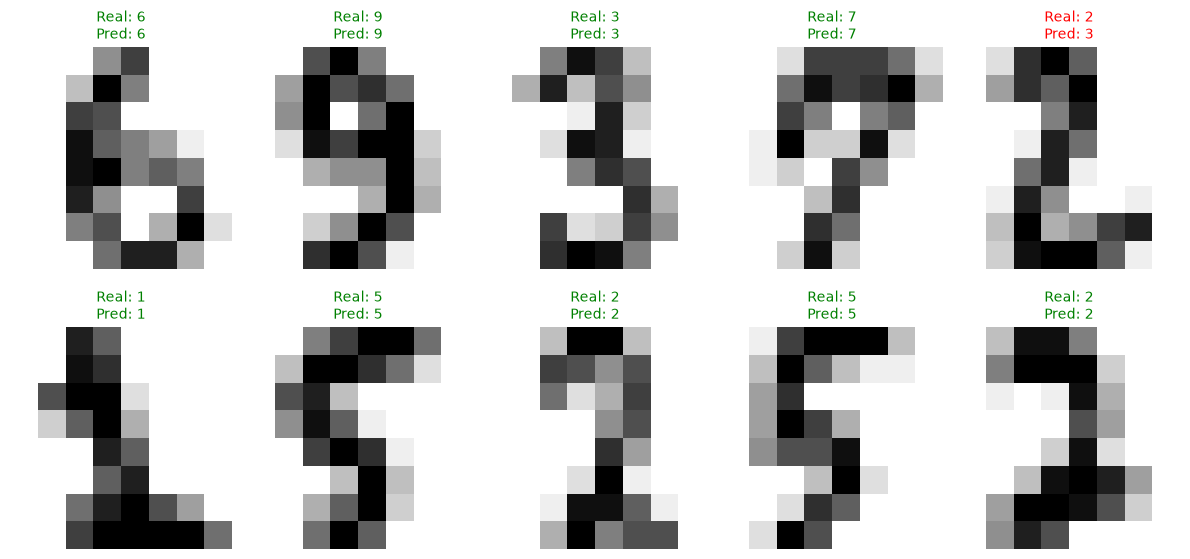

In [8]:
# Paso 6: Visualización de Predicciones Individuales
fig, axes = plt.subplots(2, 5, figsize=(12, 6))
for i, ax in enumerate(axes.flat):
    # Tomamos las primeras 10 imágenes de test
    image = X_test[i].reshape(8, 8)
    real_label = y_test[i]
    pred_label = y_pred[i]
    
    color = 'green' if real_label == pred_label else 'red'
    
    ax.imshow(image, cmap='gray_r')
    ax.set_title(f"Real: {real_label}\nPred: {pred_label}", color=color, fontsize=10)
    ax.axis('off')

plt.tight_layout()
plt.show()

--- # Actividades
1. **Modificar la arquitectura:** Cambia `hidden_layer_sizes=(64, 32)` a una sola capa oculta de 16 neuronas `(16,)` y compara la precisión.
2. **Cambiar la función de activación:** Experimenta usando `activation='logistic'` (sigmoide) o `activation='tanh'`. ¿Cómo afecta los resultados?
3. **Analizar errores:** Encuentra alguna imagen que el modelo haya clasificado incorrectamente y analiza por qué se pudo haber confundido.

## Actividades resueltas

En las tres pruebas se conserva la misma división de entrenamiento y prueba (`random_state=42`) para que la comparación sea justa. Se usa `max_iter=300`, igual que en el modelo original.


### Actividad 1. Modificar la arquitectura

Cambiamos las dos capas ocultas `(64, 32)` por una sola capa oculta de 16 neuronas `(16,)`. Mantenemos `relu` como función de activación y los demás parámetros.


In [ ]:
# Actividad 1: una sola capa oculta con 16 neuronas
mlp_16 = MLPClassifier(
    hidden_layer_sizes=(16,),
    activation='relu',
    max_iter=300,
    random_state=42
)

mlp_16.fit(X_train, y_train)
y_pred_16 = mlp_16.predict(X_test)

accuracy_16 = accuracy_score(y_test, y_pred_16)
accuracy_original = accuracy_score(y_test, y_pred)

print(f"Precisión del modelo original (64, 32): {accuracy_original * 100:.2f}%")
print(f"Precisión con una capa de 16 neuronas: {accuracy_16 * 100:.2f}%")
print(f"Diferencia: {(accuracy_16 - accuracy_original) * 100:+.2f} puntos porcentuales")


**Interpretación:** el modelo original obtuvo **96.67 %** y el modelo con una sola capa de 16 neuronas obtuvo **96.39 %**. La precisión disminuyó ligeramente (0.28 puntos porcentuales). La arquitectura más pequeña utiliza menos neuronas y es más sencilla, pero en esta prueba reconoció un poco menos de imágenes correctamente.


### Actividad 2. Cambiar la función de activación

Ahora conservamos la arquitectura de una capa con 16 neuronas y probamos `logistic` (sigmoide) y `tanh`. Así comparamos el efecto de cambiar únicamente la función de activación.


In [ ]:
# Actividad 2: comparar funciones de activación
resultados_activacion = {}

for activacion in ['logistic', 'tanh']:
    modelo = MLPClassifier(
        hidden_layer_sizes=(16,),
        activation=activacion,
        max_iter=300,
        random_state=42
    )

    modelo.fit(X_train, y_train)
    predicciones = modelo.predict(X_test)
    precision = accuracy_score(y_test, predicciones)
    resultados_activacion[activacion] = precision

    print(f"Activación {activacion}: {precision * 100:.2f}%")


**Resultados de la comparación:**

| Configuración | Precisión |
|---|---:|
| Original: `(64, 32)` + `relu` | **96.67 %** |
| Una capa `(16,)` + `relu` | **96.39 %** |
| Una capa `(16,)` + `logistic` | **95.00 %** |
| Una capa `(16,)` + `tanh` | **96.11 %** |

**Interpretación:** en esta ejecución, `relu` obtuvo el mejor resultado entre las pruebas con 16 neuronas. `tanh` quedó ligeramente por debajo y `logistic` obtuvo la precisión más baja. Esto muestra que la función de activación influye en la capacidad de aprendizaje de la red y en sus predicciones.

**Nota:** con `max_iter=300`, los tres modelos de 16 neuronas alcanzaron el límite de iteraciones antes de converger. Por eso, los porcentajes son los resultados obtenidos con ese límite; se podría probar `max_iter=1000` para permitir un entrenamiento más largo.


### Actividad 3. Analizar errores de clasificación

Revisaremos una imagen del conjunto de prueba que el modelo original clasificó incorrectamente. La primera imagen incorrecta de esta ejecución tiene como valor real el número **2**, pero el modelo predijo **3**.


In [ ]:
# Actividad 3: localizar y visualizar una predicción incorrecta
errores = np.where(y_test != y_pred)[0]

print(f"Imágenes clasificadas incorrectamente: {len(errores)} de {len(y_test)}")

if len(errores) > 0:
    posicion_error = errores[0]
    valor_real = y_test[posicion_error]
    valor_predicho = y_pred[posicion_error]

    print(f"Posición dentro del conjunto de prueba: {posicion_error}")
    print(f"Valor real: {valor_real}")
    print(f"Predicción del modelo: {valor_predicho}")

    plt.figure(figsize=(3, 3))
    plt.imshow(X_test[posicion_error].reshape(8, 8), cmap='gray_r')
    plt.title(f"Real: {valor_real} | Predicción: {valor_predicho}")
    plt.axis('off')
    plt.show()
else:
    print("No se encontraron errores.")


**Análisis del error:** el modelo confundió un número **2** con un **3**. Una posible explicación es que las imágenes tienen una resolución pequeña de solo 8 × 8 píxeles (64 valores). Al tener pocos píxeles, algunos trazos curvos o la forma de los números pueden parecerse. Si la escritura no es muy clara, la red puede encontrar características similares entre ambos números y elegir una clase equivocada.

El modelo original acertó 348 de las 360 imágenes y se equivocó en 12, lo que corresponde a una precisión de 96.67 %.


## Conclusión general

La práctica permitió comprobar que tanto la arquitectura como la función de activación afectan el desempeño de una red neuronal. El modelo original, con dos capas ocultas de 64 y 32 neuronas y activación `relu`, obtuvo la mayor precisión (**96.67 %**) en estas pruebas. Al reducir la arquitectura a una sola capa de 16 neuronas, la precisión fue de **96.39 %**. Con esa misma arquitectura, `logistic` obtuvo **95.00 %** y `tanh` **96.11 %**.

Finalmente, se observó que el modelo puede confundir números visualmente parecidos debido a la baja resolución de las imágenes y a las similitudes en sus trazos. Por lo tanto, una buena arquitectura y una función de activación adecuada ayudan a mejorar la clasificación, pero no eliminan todos los errores.
